# Entrenamiento del XGBoost con canales enmascarados

El objetivo de este notebook es entrenar un **único XGBoost** que clasifique cada época en W, N1, N2, N3 o REM con cualquiera de las 12 combinaciones de canales. Para lograrlo, en el entrenamiento se "apagan" canales al azar: sus columnas se ponen en NaN, y el modelo aprende a clasificar con lo que tenga.

La entrada es la tabla de 719 rasgos de `1_preprocesamiento.ipynb`. El modelo final queda en `modelo/modelo_a_xgboost/`: `xgb.json` (los árboles) y `columnas.json` (los rasgos de entrada, en orden).

El notebook se organiza así:

1. **Librerías**
2. **Rutas y parámetros**
3. **Datos:** partición por sujeto, combinaciones de canales y tabla de rasgos.
4. **Enmascaramiento de canales**
5. **Entrenamiento:** validación cruzada y modelo final.
6. **Resultados:** métricas por combinación, F1 por estadio y matrices de confusión.
7. **Usar el modelo guardado**
8. **Conclusiones**

## 1. Librerías

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 2. Rutas y parámetros

Con `PRUEBA = True` se entrena 1 fold con 50 rondas, solo para comprobar que todo corre.

In [2]:
# Raíz del repositorio: la carpeta que tiene particiones.json
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "particiones.json").exists())
PROCESADOS = RAIZ / "data" / "procesados" / "modelo_a_xgboost"
MODELO = RAIZ / "modelo" / "modelo_a_xgboost"

SEED = 42
PRUEBA = False
ESTADIOS = ["W", "N1", "N2", "N3", "REM"]

## 3. Datos

### Partición por sujeto

`particiones.json` fija 16 sujetos de test y 5 folds sobre los 62 de desarrollo. Las dos noches de una persona siempre van juntas, para que el modelo nunca se evalúe con alguien que vio en el entrenamiento. En cada fold, unos pocos sujetos de entrenamiento se separan para validación (early stopping).

In [3]:
# Sujetos por fold
particion = json.loads((RAIZ / "particiones.json").read_text())
print(f"{len(particion['sujetos_test'])} sujetos de test, {len(particion['sujetos_desarrollo'])} de desarrollo")
pd.DataFrame([{"fold": f["fold"], "entrenamiento": len(f["train"]), "validación": len(f["val"]),
               "se predicen": len(f["test"])} for f in particion["folds"]]).set_index("fold")

16 sujetos de test, 62 de desarrollo


,entrenamiento,validación,se predicen
fold,,,
0,44,5,13
1,44,5,13
2,45,5,12
3,45,5,12
4,45,5,12


### Combinaciones de canales

Las 12 combinaciones con al menos un EEG.

In [4]:
# Las 12 combinaciones
CONFIGS = {k: tuple(v) for k, v in particion["combinaciones"].items()}
pd.DataFrame({c: {ch: "✓" if ch in chans else "" for ch in ("fpz", "pz", "eog", "emg")}
              for c, chans in CONFIGS.items()}).T

,fpz,pz,eog,emg
fpz,✓,,,
pz,,✓,,
eeg2,✓,✓,,
fpz_eog,✓,,✓,
pz_eog,,✓,✓,
eeg2_eog,✓,✓,✓,
fpz_emg,✓,,,✓
pz_emg,,✓,,✓
eeg2_emg,✓,✓,,✓
fpz_eog_emg,✓,,✓,✓


### Tabla de rasgos

Leemos la tabla de `1_preprocesamiento.ipynb`.

In [5]:
# Lectura de la tabla de rasgos
META_COLS = ["night", "subject", "epoch_idx", "y"]
full = pd.read_parquet(PROCESADOS / "rasgos.parquet")
cols = [c for c in full.columns if c not in META_COLS]
print(f"tabla: {full.shape[0]:,} épocas × {len(cols)} columnas del modelo")

tabla: 195,767 épocas × 719 columnas del modelo


## 4. Enmascaramiento de canales

### Columnas de cada canal

Para cada canal armamos la lista de columnas que dependen de él, usando el prefijo. `eog_corr_fpz` queda también en la lista de Fpz-Cz: si falta Fpz-Cz, esa columna no se puede calcular aunque haya EOG.

In [6]:
# Función para saber qué columnas dependen de cada canal
CHANNELS_ALL = ("fpz", "pz", "eog", "emg")
CROSS = {"corr_fpz": "fpz"}  # rasgos con prefijo de un canal que también usan otro


def channel_index(cols):
    ch = np.array([c.split("_")[0] for c in cols])
    idx = {c: set(np.where(ch == c)[0]) for c in CHANNELS_ALL}
    for i, col in enumerate(cols):
        for key, other in CROSS.items():
            if key in col:
                idx[other].add(i)
    return {c: np.array(sorted(v), dtype=int) for c, v in idx.items()}


idx = channel_index(cols)
pd.Series({c: len(v) for c, v in idx.items()}).to_frame("columnas").T

,fpz,pz,eog,emg
columnas,280,278,132,30


### Apagar canales

En el entrenamiento, **a cada época se le sortea una de las 12 combinaciones** y las columnas de los canales ausentes se ponen en NaN. XGBoost aprende en cada división hacia qué rama mandar los valores faltantes, así que un solo modelo sirve para cualquier combinación.

In [7]:
# Funciones para poner en NaN los canales ausentes
def apply_mask(X, configs_per_row, idx):
    """Pone en NaN las columnas de los canales ausentes de cada fila. Modifica X."""
    names = np.asarray(configs_per_row)
    for cfg, chans in CONFIGS.items():
        r = np.where(names == cfg)[0]
        if len(r) == 0:
            continue
        for ch in CHANNELS_ALL:
            if ch not in chans:
                X[np.ix_(r, idx[ch])] = np.nan
    return X


def random_mask(df, cols, idx, rng):
    X = df[cols].to_numpy(np.float32, copy=True)
    return apply_mask(X, rng.choice(list(CONFIGS), size=len(X)), idx)

Ejemplo con 4 épocas, cada una con una combinación distinta: se ve qué parte de las columnas de cada canal queda apagada.

In [8]:
# Ejemplo de enmascaramiento
demo = full[full.y >= 0].head(4)[cols].to_numpy(np.float32, copy=True)
ejemplo = ["fpz", "pz_eog", "eeg2_emg", "fpz_eog_emg"]
apply_mask(demo, ejemplo, idx)
pd.DataFrame({"combinación": ejemplo, **{ch: [f"{np.isnan(r[idx[ch]]).mean():.0%} NaN" for r in demo] for ch in CHANNELS_ALL}})

,combinación,fpz,pz,eog,emg
0,fpz,15% NaN,100% NaN,100% NaN,100% NaN
1,pz_eog,100% NaN,7% NaN,6% NaN,100% NaN
2,eeg2_emg,1% NaN,0% NaN,100% NaN,0% NaN
3,fpz_eog_emg,0% NaN,100% NaN,0% NaN,0% NaN


## 5. Entrenamiento

### Hiperparámetros

Los eligió una búsqueda con optuna (TPE, 5 folds de desarrollo) en una etapa anterior del proyecto, y aquí no se vuelven a buscar. Los **pesos por clase** son balanceado^α con α = 0.44: compensan el desbalance (N3 es el 6.7 % de las épocas) sin exagerar las clases raras.

In [9]:
# Hiperparámetros del XGBoost y pesos por clase
PARAMS = {
    "objective": "multi:softprob", "tree_method": "hist", "eval_metric": "mlogloss", "n_jobs": -1,
    "learning_rate": 0.03394046833983564, "max_depth": 10, "min_child_weight": 43.70990468130503,
    "subsample": 0.9041986740582306, "colsample_bytree": 0.4436910153386966,
    "reg_lambda": 0.019634341572933336, "gamma": 3.4211651325607844,
}
ALPHA = 0.4401524937396013
N_MAX = 50 if PRUEBA else 2000


def class_weights(y, alpha=ALPHA):
    return compute_sample_weight("balanced", y) ** alpha

### Funciones de entrenamiento y predicción

- `fit`: entrena con los sujetos dados, con los canales enmascarados al azar. Si recibe sujetos de validación, para cuando dejan de mejorar (early stopping, 100 rondas).
- `predict_all_configs`: predice a los sujetos dados con cada una de las 12 combinaciones. Incluye las épocas sin etiqueta (y = −1), para conservar la noche completa.

In [10]:
# Función para entrenar un XGBoost con canales enmascarados
def rows(subjects, labeled_only=True):
    m = full.subject.isin(list(subjects))
    return full[m & (full.y >= 0)] if labeled_only else full[m]


def fit(train_subj, rng, val_subj=None, n_estimators=N_MAX):
    tr = rows(train_subj)
    p = {**PARAMS, "random_state": SEED}
    Xtr = random_mask(tr, cols, idx, rng)
    if val_subj is None:
        model = xgb.XGBClassifier(**p, n_estimators=n_estimators)
        model.fit(Xtr, tr.y, sample_weight=class_weights(tr.y), verbose=False)
        return model
    va = rows(val_subj)
    Xva = random_mask(va, cols, idx, rng)
    model = xgb.XGBClassifier(**p, n_estimators=n_estimators, early_stopping_rounds=100)
    model.fit(Xtr, tr.y, sample_weight=class_weights(tr.y), eval_set=[(Xva, va.y)],
              sample_weight_eval_set=[class_weights(va.y)], verbose=False)
    return model

In [11]:
# Funciones para predecir con las 12 combinaciones y guardar las predicciones
def predict_all_configs(model, subjects):
    """combinación -> noche -> (y, probabilidades), con todas las épocas enmascaradas igual."""
    d = rows(subjects, labeled_only=False)
    base_x = d[cols].to_numpy(np.float32)
    groups = d.groupby("night").indices
    out = {}
    for cfg in CONFIGS:
        proba = model.predict_proba(apply_mask(base_x.copy(), [cfg] * len(base_x), idx))
        out[cfg] = {n: (d.y.values[i], proba[i]) for n, i in groups.items()}
    return out


def save_preds(path, preds):
    arr = {}
    for cfg, p in preds.items():
        for n, (y, pr) in p.items():
            arr[f"{cfg}__{n}__y"], arr[f"{cfg}__{n}__pred"] = y, pr
    np.savez_compressed(path, **arr)


def load_preds(path):
    z = np.load(path)
    out = {}
    for k in z.files:
        cfg, n, kind = k.split("__")
        if kind == "y":
            out.setdefault(cfg, {})[n] = (z[k], z[f"{cfg}__{n}__pred"])
    return out

### Validación cruzada (5 folds)

En cada fold entrenamos con ~44 sujetos, hacemos early stopping con los ~5 de validación (también enmascarados) y predecimos los ~13 restantes con las 12 combinaciones. Juntando los 5 folds se obtienen las **predicciones fuera de fold** de las 62 personas de desarrollo.

Cada sorteo de máscaras tiene su semilla (`[42, fold]`). Las predicciones de cada fold se guardan en `data/procesados/modelo_a_xgboost/folds/`: si se corta, al volver a correr retoma desde el último fold guardado.

In [12]:
# Validación cruzada: un modelo por fold
FOLDS = PROCESADOS / ("folds_prueba" if PRUEBA else "folds")
FOLDS.mkdir(exist_ok=True)
folds = particion["folds"][:1] if PRUEBA else particion["folds"]

rondas = []
for f in folds:
    path, meta = FOLDS / f"fold_{f['fold']}.npz", FOLDS / f"fold_{f['fold']}.json"
    if not meta.exists():
        rng = np.random.default_rng([SEED, f["fold"]])
        m = fit(f["train"], rng, val_subj=f["val"])
        save_preds(path, predict_all_configs(m, f["test"]))
        meta.write_text(json.dumps({"rondas": m.best_iteration + 1}))
    rondas.append(json.loads(meta.read_text())["rondas"])
    print(f"fold {f['fold'] + 1}: {rondas[-1]} rondas")

fold 1: 592 rondas
fold 2: 656 rondas
fold 3: 660 rondas
fold 4: 508 rondas
fold 5: 644 rondas


### Modelo final

Entrenamos con los 62 sujetos de desarrollo, sin validación, con el promedio de rondas de los folds (semilla de máscaras `[42, 99]`). Predice el **test de 16 sujetos** con las 12 combinaciones y se guarda en `modelo/modelo_a_xgboost/`.

In [13]:
# Modelo final con los 62 sujetos de desarrollo
n_final = int(np.mean(rondas))
final_path = FOLDS / "final.npz"
if not final_path.exists():
    final = fit(particion["sujetos_desarrollo"], np.random.default_rng([SEED, 99]), n_estimators=n_final)
    save_preds(final_path, predict_all_configs(final, particion["sujetos_test"]))
    if not PRUEBA:
        MODELO.mkdir(parents=True, exist_ok=True)
        final.save_model(MODELO / "xgb.json")
        (MODELO / "columnas.json").write_text(json.dumps(cols))
        print("guardado:", MODELO.relative_to(RAIZ))
print(f"modelo final: {n_final} rondas")

guardado: modelo/xgboost
modelo final: 612 rondas


Juntamos las predicciones fuera de fold de los 5 folds y las de test.

In [14]:
# Predicciones fuera de fold (CV) y de test
oof = {c: {} for c in CONFIGS}
for f in folds:
    for c, p in load_preds(FOLDS / f"fold_{f['fold']}.npz").items():
        oof[c].update(p)
test = load_preds(final_path)

## 6. Resultados

### Métricas

- **F1 macro (MF1):** la principal. Es el promedio del F1 de los 5 estadios con el mismo peso, así que N1, que es el 11 % de las épocas y el más difícil, cuenta tanto como N2.
- **κ de Cohen:** acuerdo con el técnico descontando el azar.
- **F1 de N1.**

Solo se evalúan las épocas con etiqueta.

In [15]:
# Funciones para calcular las métricas
def compute_metrics(y_true, y_pred):
    f1 = f1_score(y_true, y_pred, labels=range(5), average=None, zero_division=0)
    return {"acc": accuracy_score(y_true, y_pred), "mf1": f1.mean(), "kappa": cohen_kappa_score(y_true, y_pred),
            **{f"f1_{s}": v for s, v in zip(ESTADIOS, f1)},
            "confusion": confusion_matrix(y_true, y_pred, labels=range(5))}


def metrics_of(preds):
    y = np.concatenate([y for y, _ in preds.values()])
    p = np.concatenate([p.argmax(1) for _, p in preds.values()])
    return compute_metrics(y[y >= 0], p[y >= 0])

### Por combinación

**CV:** predicciones fuera de fold de los 62 sujetos de desarrollo. **Test:** los 16 sujetos que no se usaron para ninguna decisión.

In [16]:
# Métricas de CV y de test por combinación
filas = []
for c in CONFIGS:
    cv, te = metrics_of(oof[c]), metrics_of(test[c])
    filas.append({"combinación": c, "CV MF1": cv["mf1"], "CV κ": cv["kappa"], "CV F1 N1": cv["f1_N1"],
                  "test MF1": te["mf1"], "test κ": te["kappa"], "test F1 N1": te["f1_N1"]})
pd.DataFrame(filas).set_index("combinación").style.format(precision=3)

,CV MF1,CV κ,CV F1 N1,test MF1,test κ,test F1 N1
combinación,,,,,,
fpz,0.769,0.751,0.461,0.727,0.702,0.405
pz,0.728,0.721,0.433,0.701,0.672,0.414
eeg2,0.784,0.773,0.488,0.745,0.721,0.452
fpz_eog,0.788,0.774,0.498,0.755,0.728,0.467
pz_eog,0.765,0.758,0.493,0.724,0.693,0.452
eeg2_eog,0.799,0.789,0.518,0.761,0.736,0.478
fpz_emg,0.776,0.758,0.476,0.737,0.709,0.430
pz_emg,0.736,0.729,0.453,0.714,0.681,0.442
eeg2_emg,0.789,0.778,0.501,0.753,0.728,0.469


### F1 por estadio

Comparamos solo Fpz-Cz con los 4 canales, en el test.

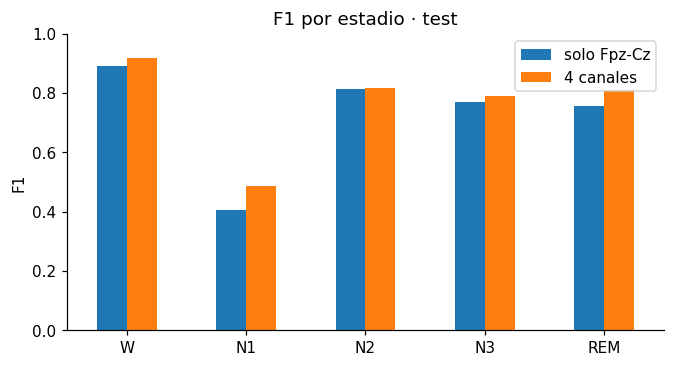

In [17]:
# F1 por estadio en el test
f1 = pd.DataFrame({nombre: [metrics_of(test[c])[f"f1_{s}"] for s in ESTADIOS]
                   for c, nombre in [("fpz", "solo Fpz-Cz"), ("eeg2_eog_emg", "4 canales")]}, index=ESTADIOS)
ax = f1.plot.bar(figsize=(7, 3.5), rot=0)
ax.set_ylabel("F1")
ax.set_ylim(0, 1)
ax.set_title("F1 por estadio · test")
plt.show()

### Matrices de confusión

Test (16 sujetos), solo con Fpz-Cz y con los 4 canales. Cada fila es el estadio real y suma 100 %.

In [18]:
# Función para graficar una matriz de confusión
def plot_confusion(cm, title, ax):
    cm = np.asarray(cm)
    cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{cmn[i, j]:.0%}\n{cm[i, j]:,}", ha="center", va="center", fontsize=8,
                    color="white" if cmn[i, j] > 0.6 else "black")
    ax.set_xticks(range(5), ESTADIOS)
    ax.set_yticks(range(5), ESTADIOS)
    ax.set_xlabel("predicho")
    ax.set_ylabel("real")
    ax.set_title(title, fontsize=10)

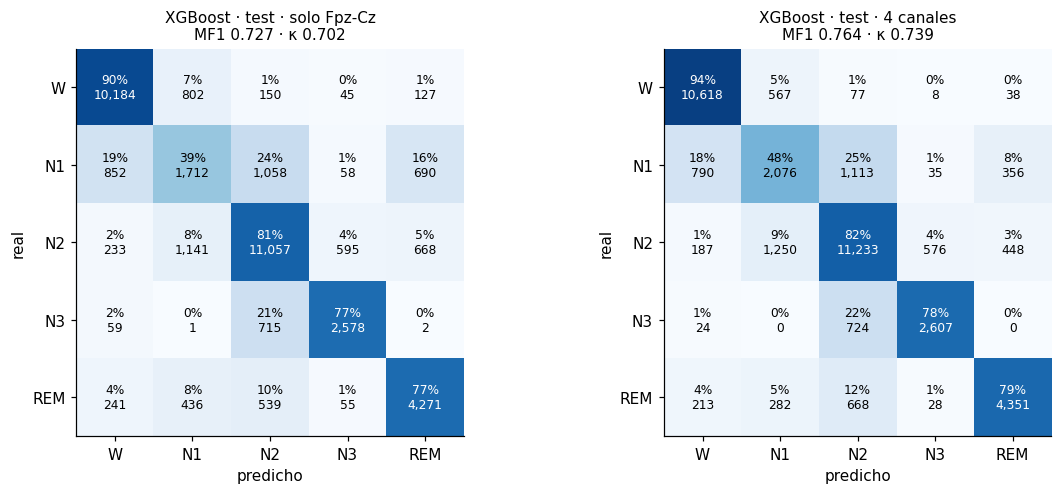

In [19]:
# Matrices de confusión del test
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, c, nombre in zip(axes, ["fpz", "eeg2_eog_emg"], ["solo Fpz-Cz", "4 canales"]):
    m = metrics_of(test[c])
    plot_confusion(m["confusion"], f"XGBoost · test · {nombre}\nMF1 {m['mf1']:.3f} · κ {m['kappa']:.3f}", ax)
plt.tight_layout()
plt.show()

## 7. Usar el modelo guardado

Para predecir no hace falta reentrenar: basta con cargar `xgb.json` y pasarle los rasgos en el orden de `columnas.json`, con los canales ausentes en NaN. Predecimos una noche de test solo con Fpz-Cz y comprobamos que da lo mismo que el modelo recién entrenado.

In [20]:
# Cargar el modelo guardado y predecir una noche de test con Fpz-Cz
modelo = xgb.Booster()
modelo.load_model(MODELO / "xgb.json")
columnas = json.loads((MODELO / "columnas.json").read_text())

noche = sorted(test["fpz"])[0]
d = full[full.night == noche]
X = apply_mask(d[columnas].to_numpy(np.float32), ["fpz"] * len(d), channel_index(columnas))
proba = modelo.predict(xgb.DMatrix(X))
assert np.allclose(proba, test["fpz"][noche][1], atol=1e-6)

y, pred = d.y.values, proba.argmax(1)
m = compute_metrics(y[y >= 0], pred[y >= 0])
print(f"{noche}, solo Fpz-Cz: {len(d)} épocas · MF1 {m['mf1']:.3f} · κ {m['kappa']:.3f}")

SC4001, solo Fpz-Cz: 841 épocas · MF1 0.785 · κ 0.837


In [21]:
# Las primeras épocas de esa noche: estadio real, predicho y confianza del modelo
pd.DataFrame({"real": [ESTADIOS[v] if v >= 0 else "?" for v in y[:10]],
              "predicho": [ESTADIOS[v] for v in pred[:10]],
              "confianza": proba[:10].max(1).round(2)})

,real,predicho,confianza
0,W,W,1.00
1,W,W,1.00
2,W,W,1.00
3,W,W,1.00
4,W,W,1.00
5,W,W,1.00
6,W,W,1.00
7,W,W,0.99
8,W,W,1.00
9,W,W,0.99


## 8. Conclusiones

- Un solo XGBoost sirve para las 12 combinaciones de canales: al apagar canales al azar en el entrenamiento, aprende a clasificar con lo que tenga.
- Agregar canales mejora el resultado: los 4 canales superan a un EEG solo.
- La clase más difícil es **N1**: se confunde con W y con N2, porque es la transición entre la vigilia y el sueño.